In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

In [3]:
from tensorflow.keras import layers,models
from sklearn.metrics import classification_report, confusion_matrix

In [4]:
#loading the dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training:", x_train.shape)
print("Testing:", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training: (60000, 28, 28)
Testing: (10000, 28, 28)


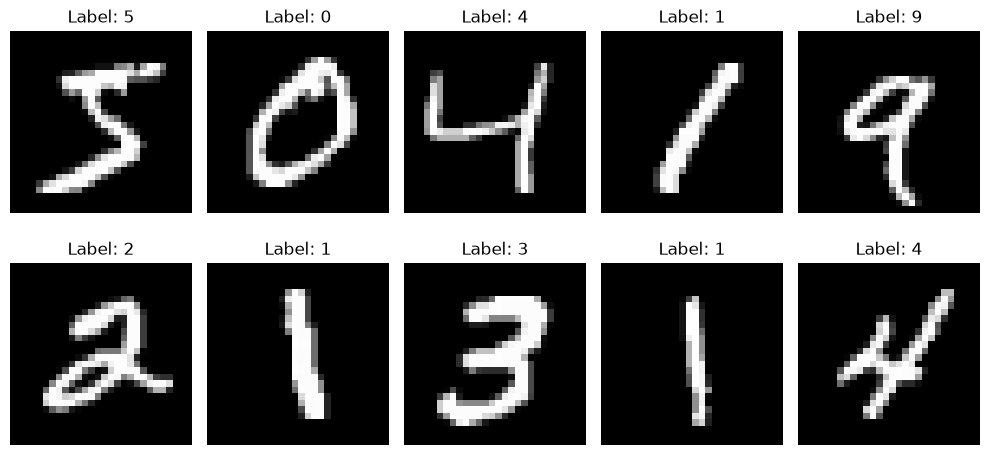

In [5]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
#preprocessing the images

In [7]:
#normalize to 0-1

In [8]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add channel dimension
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print(x_train.shape)
print(x_test.shape)

(60000, 28, 28, 1)
(10000, 28, 28, 1)


In [9]:
#now the CNN architecture

In [24]:
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    #32 filter , ReLU
    layers.Conv2D(8, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    #64 filter ,ReLU
    layers.Conv2D(16, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    #flatten and dense
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    #dropout 30%
    layers.Dropout(0.3),
    #output softmax 10 p
    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 13, 13, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 11, 11, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │        25,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,562 (107.66 KB)

 Trainable params: 27,562 (107.66 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    x_train,
    y_train,
    epochs=8,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8934 - loss: 0.3525 - val_accuracy: 0.9748 - val_loss: 0.0862
Epoch 2/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9612 - loss: 0.1268 - val_accuracy: 0.9787 - val_loss: 0.0721
Epoch 3/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9700 - loss: 0.0989 - val_accuracy: 0.9832 - val_loss: 0.0630
Epoch 4/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9737 - loss: 0.0856 - val_accuracy: 0.9845 - val_loss: 0.0545
Epoch 5/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9767 - loss: 0.0754 - val_accuracy: 0.9848 - val_loss: 0.0552
Epoch 6/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9792 - loss: 0.0667 - val_accuracy: 0.9867 - val_loss: 0.0507
Epoch 7/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9807 - loss: 0.0611 - val_accuracy: 0.9858 - val_loss: 0.0510
Epoch 8/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9821 - loss: 0.0569 - val_accuracy: 0.9853 - v

In [26]:
# We use sparse_categorical_crossentropy because MNIST labels are integers from 0 to 9, rather than one-hot encoded vectors.

In [27]:
test_loss, test_accuracy = model.evaluate(
    x_test, y_test, verbose=0
)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")

Test Accuracy: 0.9876
Test Loss: 0.0363


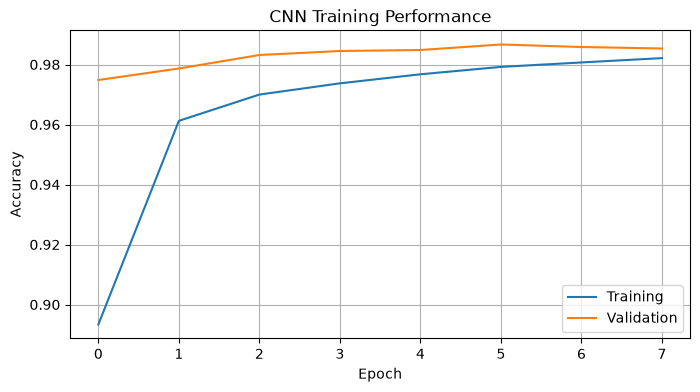

In [28]:
plt.figure(figsize=(8, 4))

plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training Performance")
plt.legend()
plt.grid(True)
plt.show()

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.98      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.98      0.99      0.98       892
           6       1.00      0.99      0.99       958
           7       0.99      0.98      0.98      1028
           8       0.99      0.98      0.99       974
           9       0.99      0.98      0.98      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



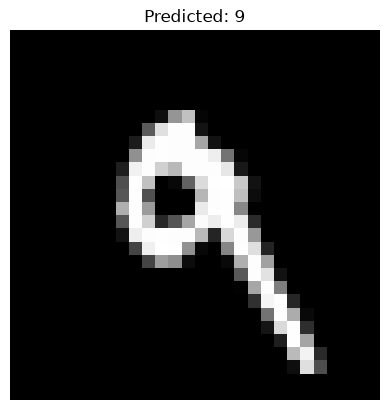

In [31]:
predictions = model.predict(x_test, verbose=0)

predicted_labels = np.argmax(predictions, axis=1)

print(classification_report(y_test, predicted_labels))

# Display one prediction
index = 7

plt.imshow(x_test[index].squeeze(), cmap="gray")
plt.title(f"Predicted: {predicted_labels[index]}")
plt.axis("off")
plt.show()